In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [3]:
df = pd.read_csv('C:/Users/iskit/Desktop/Machine-Learning-Studies/03-MachineLearning/datasets/fraud_detection.csv')

In [5]:
df.columns

Index(['transaction_amount', 'transaction_risk_score', 'is_fraud'], dtype='object')

In [6]:
df.head()

,transaction_amount,transaction_risk_score,is_fraud
0,1.879910,-1.485035,0
1,0.377083,-2.238585,0
2,1.354312,-2.664638,0
3,-0.509843,-1.502950,0
4,0.863561,-1.906364,0


In [8]:
df['is_fraud'].unique()

array([0, 1])

In [9]:
df['is_fraud'].value_counts()

is_fraud
0    9846
1     154
Name: count, dtype: int64

In [10]:
# imbalanced dataset

In [11]:
df.isnull().sum()

transaction_amount        0
transaction_risk_score    0
is_fraud                  0
dtype: int64

In [12]:
X = df.drop('is_fraud',axis=1)
y = df['is_fraud']

<Axes: xlabel='transaction_amount', ylabel='transaction_risk_score'>

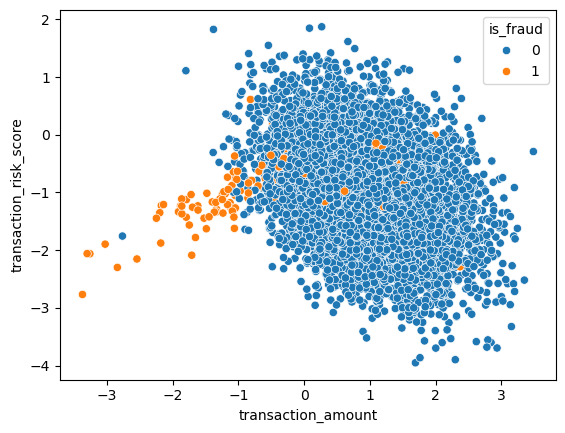

In [13]:
sns.scatterplot(x=X['transaction_amount'],y=X['transaction_risk_score'],hue=y)

In [14]:
from sklearn.model_selection import train_test_split

In [15]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.25,random_state=42)

In [16]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression()

In [17]:
penalty = ['l1','l2','elasticnet']
c_values = [100,10,1,0.1,0.01]
solver = ['lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga']
class_weight = [{0:w , 1:y} for w in [1,10,50,100] for y in [1,10,50,100]]

In [18]:
class_weight

[{0: 1, 1: 1},
 {0: 1, 1: 10},
 {0: 1, 1: 50},
 {0: 1, 1: 100},
 {0: 10, 1: 1},
 {0: 10, 1: 10},
 {0: 10, 1: 50},
 {0: 10, 1: 100},
 {0: 50, 1: 1},
 {0: 50, 1: 10},
 {0: 50, 1: 50},
 {0: 50, 1: 100},
 {0: 100, 1: 1},
 {0: 100, 1: 10},
 {0: 100, 1: 50},
 {0: 100, 1: 100}]

In [26]:
params = dict(penalty = penalty , C = c_values, solver = solver , class_weight = class_weight)

In [27]:
from sklearn.model_selection import GridSearchCV,StratifiedKFold

In [28]:
cv = StratifiedKFold()

In [29]:
grid = GridSearchCV(estimator=model,param_grid=params,scoring='accuracy',cv=cv)

In [30]:
import warnings
warnings.filterwarnings('ignore')

In [31]:
grid.fit(X_train,y_train)

,estimator,LogisticRegression()
,param_grid,"{'C': [100, 10, ...], 'class_weight': [{0: 1, 1: 1}, {0: 1, 1: 10}, ...], 'penalty': ['l1', 'l2', ...], 'solver': ['lbfgs', 'liblinear', ...]}"
,scoring,'accuracy'
,n_jobs,None
,refit,True
,cv,StratifiedKFo...shuffle=False)
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,penalty,'l1'


In [36]:
y_pred = grid.predict(X_test)

In [37]:
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix

In [38]:
print('score :',accuracy_score(y_pred,y_test))
print(classification_report(y_pred,y_test))
print('confusion matrix :\n',confusion_matrix(y_pred,y_test))

score : 0.9896
              precision    recall  f1-score   support

           0       1.00      0.99      0.99      2491
           1       0.26      1.00      0.41         9

    accuracy                           0.99      2500
   macro avg       0.63      0.99      0.70      2500
weighted avg       1.00      0.99      0.99      2500

confusion matrix :
 [[2465   26]
 [   0    9]]


In [39]:
grid.best_params_

{'C': 100,
 'class_weight': {0: 50, 1: 100},
 'penalty': 'l1',
 'solver': 'liblinear'}

In [40]:
# roc , auc

In [46]:
model_probolity = grid.predict_proba(X_test)

In [47]:
model_probolity

array([[0.92404013, 0.07595987],
       [0.99672086, 0.00327914],
       [0.94228429, 0.05771571],
       ...,
       [0.92178658, 0.07821342],
       [0.9877336 , 0.0122664 ],
       [0.97176535, 0.02823465]], shape=(2500, 2))

In [48]:
# probolities for the positive (fraud) class
model_probolity = model_probolity[:,1]

In [49]:
model_probolity

array([0.07595987, 0.00327914, 0.05771571, ..., 0.07821342, 0.0122664 ,
       0.02823465], shape=(2500,))

In [50]:
from sklearn.metrics import roc_curve , roc_auc_score

In [52]:
model_auc = roc_auc_score(y_test,model_probolity)

In [53]:
model_auc

0.7266183714865255

In [56]:
# model false positive rate - model true positive rate
model_fpr , model_tpr , thresholds = roc_curve(y_test,model_probolity)

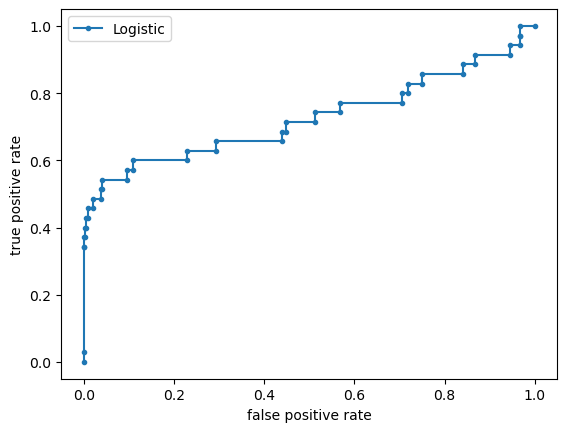

In [57]:
plt.plot(model_fpr,model_tpr,marker='.',label='Logistic')
plt.xlabel('false positive rate')
plt.ylabel('true positive rate')
plt.legend()
plt.show()

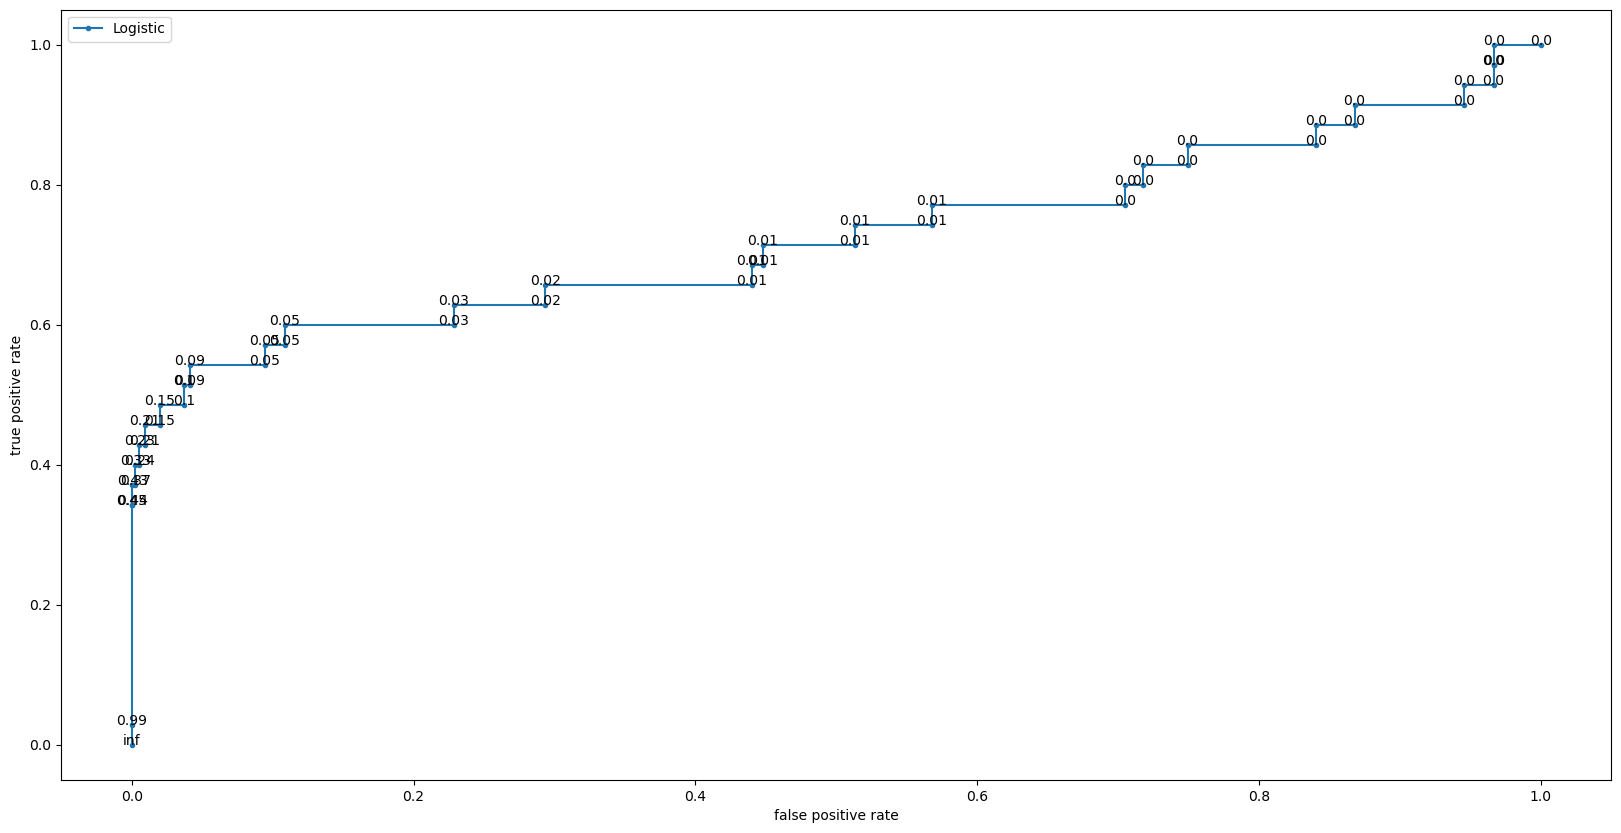

In [59]:
fig,ax = plt.subplots(figsize=(20,10))
ax.plot(model_fpr,model_tpr,marker='.',label='Logistic')
for fpr , tpr , thresh in zip(model_fpr,model_tpr,thresholds):
    ax.annotate(f'{np.round(thresh,2)}',(fpr,tpr),ha='center')
ax.set_xlabel('false positive rate')
ax.set_ylabel('true positive rate')
ax.legend()
plt.show()

In [66]:
custom_threshold = 0.5
y_pred_custom = (model_probolity >= custom_threshold).astype(int)
print(confusion_matrix(y_pred_custom,y_test))
print(classification_report(y_pred_custom,y_test))

[[2465   26]
 [   0    9]]
              precision    recall  f1-score   support

           0       1.00      0.99      0.99      2491
           1       0.26      1.00      0.41         9

    accuracy                           0.99      2500
   macro avg       0.63      0.99      0.70      2500
weighted avg       1.00      0.99      0.99      2500



In [61]:
y_pred_custom

array([0, 0, 0, ..., 0, 0, 0], shape=(2500,))